# Лабораторная работа №3: Foundation models для сегментации: SAM/SAM 2
## Стрельченко Алексей Александрович

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Получить маски по point и box prompts.
- Автоматически сформировать prompts из GT или детектора.
- Сравнить zero-shot и refinement head.


## Теоретическая часть

Promptable segmentation оценивает маску $M=f(I,p)$ по изображению и prompt $p$ (точка, box или маска). SAM разделяет тяжёлый image encoder и лёгкий prompt/mask decoder, поэтому один embedding изображения можно использовать для многих запросов.

![SAM architecture](https://raw.githubusercontent.com/facebookresearch/segment-anything/main/assets/model_diagram.png)


### Математическая постановка

Качество promptable-модели оценивают не только IoU, но и числом взаимодействий до достижения целевого качества: $N@IoU\geq\tau$. Для ускорения разметки важна доля масок, принимаемых без существенной коррекции.


### Материалы

- [Segment Anything](https://github.com/facebookresearch/segment-anything)
- [Transformers SAM docs](https://huggingface.co/docs/transformers/model_doc/sam)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Получить маски по point и box prompts.
2. Автоматически сформировать prompts из GT или детектора.
3. Сравнить zero-shot и refinement head.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** SAM ViT-B/MobileSAM inference, frozen encoder.
- **Ограничение данных:** до 200 изображений 512 px.
- **Fallback:** CPU на 20 изображениях или MobileSAM.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и обучению; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [8]:
# ============================================================
# НАСТРОЙКА ОКРУЖЕНИЯ (подготовительная ячейка)
# ============================================================
from pathlib import Path
import json, os, random, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import statistics as st
from scipy import ndimage

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Subset, TensorDataset
from torchvision.datasets import OxfordIIITPet
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode
from torchvision.models.segmentation import (
    lraspp_mobilenet_v3_large,
    LRASPP_MobileNet_V3_Large_Weights,
)

from transformers import SamModel, SamProcessor

# --- Глобальные настройки ---
SEED = 42
FAST_DEV_RUN = False
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Устройство и потоки CPU ---
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(os.cpu_count() or 4)
    print(f"Используется CPU с {torch.get_num_threads()} потоками.")
else:
    print(f"Используется GPU: {torch.cuda.get_device_name(0)}")

# --- Пути ---
CWD = Path.cwd().resolve()
_CANDIDATES = [CWD / "data", CWD.parent / "data", CWD.parent.parent / "data"]
_env = os.getenv("CV_COURSE_DATA")
if _env:
    DATA_ROOT = Path(_env).resolve()
else:
    DATA_ROOT = next((c for c in _CANDIDATES if (c / "oxford_pet").exists()), _CANDIDATES[0])
DATA_ROOT.mkdir(parents=True, exist_ok=True)

ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", CWD / "artifacts"))
ARTIFACTS.mkdir(parents=True, exist_ok=True)

print(f"Data root: {DATA_ROOT}")
print(f"Artifacts: {ARTIFACTS}")

# --- Константы ---
IMG_SIZE = 128   # размер для supervised baseline
SIDE = 1024      # размер для SAM
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

c:\Users\User\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Используется CPU с 16 потоками.
Data root: C:\Users\User\Desktop\ml_labs\SOTA_labs\data
Artifacts: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts


In [9]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Загрузка SAM и отложенных масок

*Вес: 1 балл.*

**Постановка.** Сравнение prompts возможно лишь на одних размеченных изображениях.

Выполните следующие действия:
1. Загрузите pretrained SAM и test Oxford-IIIT Pet.
2. Зафиксируйте индексы проверки.

**Результат.** dataset_manifest.json и объекты processor, model, eval_ds.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
# ============================================================
# ЗАДАНИЕ 1: Загрузка SAM и отложенных масок
# ============================================================
from transformers import SamModel, SamProcessor

print("Загрузка pretrained SAM (facebook/sam-vit-base)...")
processor = SamProcessor.from_pretrained("facebook/sam-vit-base")
sam_model = SamModel.from_pretrained("facebook/sam-vit-base").to(DEVICE)
sam_model.eval()
print("SAM загружен.")

# Отложенный набор для всех последующих сравнений
eval_ds = test_ds

# Фиксируем индексы проверки
N_EVAL = 50 if not FAST_DEV_RUN else 10
eval_indices = test_idx[:N_EVAL]

manifest = {
    "device": DEVICE,
    "seed": SEED,
    "n_total": n_total,
    "n_train": len(train_idx),
    "n_val": len(val_idx),
    "n_test": len(test_idx),
    "eval_indices": [int(i) for i in eval_indices],
    "sam_checkpoint": "facebook/sam-vit-base",
    "img_size_supervised": IMG_SIZE,
    "side_sam": SIDE,
}
with open(ARTIFACTS / "dataset_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print(f"dataset_manifest.json сохранён, eval содержит {len(eval_indices)} изображений")

Загрузка pretrained SAM (facebook/sam-vit-base)...


Loading weights: 100%|██████████| 314/314 [00:00<00:00, 581.56it/s]

SAM загружен.
dataset_manifest.json сохранён, eval содержит 50 изображений


### Геометрия подсказок и IoU

*Вес: 1 балл.*

**Постановка.** Box и point должны воспроизводимо извлекаться из одной истинной маски.

Выполните следующие действия:
1. Реализуйте IoU масок и ограничивающий прямоугольник.
2. Документируйте, что подсказки из GT моделируют действия разметчика.

**Результат.** Функции iou и box_from_mask.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [12]:
# ============================================================
# ЗАДАНИЕ 2: Геометрия подсказок и IoU
# ============================================================
def iou(pred_mask, gt_mask):
    """IoU двух бинарных масок (numpy или torch → приводим к numpy)."""
    if hasattr(pred_mask, "cpu"):
        pred_mask = pred_mask.cpu().numpy()
    if hasattr(gt_mask, "cpu"):
        gt_mask = gt_mask.cpu().numpy()
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)
    inter = (pred & gt).sum()
    union = (pred | gt).sum()
    return float(inter) / float(union) if union > 0 else 1.0


def box_from_mask(mask):
    """
    Ограничивающий прямоугольник [x1, y1, x2, y2] по маске.
    Подсказка моделирует действие разметчика: он очерчивает объект рамкой.
    Foreground = pet(0) ∪ border(2).
    """
    if hasattr(mask, "cpu"):
        mask = mask.cpu().numpy()
    fg = (mask == 0) | (mask == 2)
    rows = np.any(fg, axis=1)
    cols = np.any(fg, axis=0)
    if not np.any(rows) or not np.any(cols):
        return None
    y1, y2 = np.where(rows)[0][[0, -1]]
    x1, x2 = np.where(cols)[0][[0, -1]]
    return [int(x1), int(y1), int(x2), int(y2)]


def point_from_mask(mask, strategy="median"):
    """
    Point-подсказка из маски:
    - median: медиана координат пикселей (моделирует "ткнул в центр").
    - maxdist: пиксель с максимальным расстоянием до границы (бонус).
    """
    if hasattr(mask, "cpu"):
        mask = mask.cpu().numpy()
    fg = (mask == 0) | (mask == 2)
    if not np.any(fg):
        return None
    if strategy == "median":
        y, x = np.where(fg)
        return [int(np.median(x)), int(np.median(y))]
    if strategy == "maxdist":
        dist = ndimage.distance_transform_edt(fg)
        y, x = np.unravel_index(np.argmax(dist), dist.shape)
        return [int(x), int(y)]
    raise ValueError(strategy)


# Smoke
_img, _m = ds[0]
_b = box_from_mask(_m)
_p = point_from_mask(_m, "median")
_pm = point_from_mask(_m, "maxdist")
print(f"box={_b}, point(median)={_p}, point(maxdist)={_pm}")
print(f"iou(mask, mask) = {iou(_m, _m):.3f}")

box=[44, 65, 344, 495], point(median)=[182, 265], point(maxdist)=[159, 287]
iou(mask, mask) = 1.000


### Предсказание SAM по подсказке

*Вес: 1 балл.*

**Постановка.** Encoder и mask decoder должны получать корректный тип prompt.

Выполните следующие действия:
1. Подайте point или box в processor.
2. Выберите маску по предсказанной SAM оценке IoU.

**Результат.** Функция predict_sam с бинарной маской исходного размера.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# ============================================================
# ЗАДАНИЕ 3: Предсказание SAM по подсказке
# ============================================================
def predict_sam(image_pil, point=None, box=None):
    """
    Возвращает бинарную маску (H, W) в исходном размере изображения.
    Маска выбирается по предсказанной SAM оценке IoU.
    """
    if point is None and box is None:
        raise ValueError("Нужен point или box.")

    input_points = [[[point]]] if point is not None else None
    input_boxes = [[box]] if box is not None else None

    inputs = processor(
        images=image_pil,
        input_points=input_points,
        input_boxes=input_boxes,
        return_tensors="pt",
    ).to(DEVICE)

    with torch.no_grad():
        outputs = sam_model(**inputs)

    masks = processor.image_processor.post_process_masks(
        outputs.pred_masks.cpu(),
        inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu(),
    )[0]  # [1, 3, H, W]
    scores = outputs.iou_scores.cpu()[0]  # [1, 3]

    best = int(torch.argmax(scores).item())
    best_mask = masks[0, best].numpy()
    return (best_mask > 0.5).astype(np.uint8)


# Smoke
_img, _m = ds[0]
_b = box_from_mask(_m)
_m_sam = predict_sam(_img, box=_b)
print(f"SAM(box) shape={_m_sam.shape}, IoU={iou(_m_sam, (_m.numpy()==0).astype(np.uint8)):.3f}")

SAM(box) shape=(500, 394), IoU=0.797


### Сравнение point и box

*Вес: 1 балл.*

**Постановка.** Степень интерактивной подсказки влияет на качество сегментации.

Выполните следующие действия:
1. Получите две маски для каждого отложенного изображения.
2. Сохраните IoU, площади и координаты prompts.

**Результат.** prompt_results.json с реальными оценками SAM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [16]:
# ============================================================
# ЗАДАНИЕ 4: Сравнение point и box
# ============================================================
prompt_results = []
for k, i in enumerate(eval_indices):
    img, gt = ds[i]
    box = box_from_mask(gt)
    pt = point_from_mask(gt, "median")
    if box is None or pt is None:
        continue

    gt_bin = (gt.numpy() == 0).astype(np.uint8)
    m_pt = predict_sam(img, point=pt)
    m_box = predict_sam(img, box=box)

    prompt_results.append({
        "index": int(i),
        "iou_point": iou(m_pt, gt_bin),
        "iou_box": iou(m_box, gt_bin),
        "area_point": int(m_pt.sum()),
        "area_box": int(m_box.sum()),
        "area_gt": int(gt_bin.sum()),
        "point": pt,
        "box": box,
    })
    if (k + 1) % 10 == 0:
        print(f"  [{k+1}/{len(eval_indices)}]")

with open(ARTIFACTS / "prompt_results.json", "w") as f:
    json.dump(prompt_results, f, indent=2)

mean_pt = st.mean(r["iou_point"] for r in prompt_results)
mean_box = st.mean(r["iou_box"] for r in prompt_results)
print(f"[eval] mean IoU: point={mean_pt:.3f}, box={mean_box:.3f}")

  [10/50]
  [20/50]


In [23]:
# ============================================================
# ВЫВОД: результаты Задания 4 (сравнение point vs box)
# Вставлять сразу после Ячейки 4, если print'ы «потерялись» в буфере.
# ============================================================
import json
import statistics as st
from pathlib import Path

# 1. Читаем сохранённый файл
results_path = ARTIFACTS / "prompt_results.json"
with open(results_path) as f:
    data = json.load(f)

print(f"Файл: {results_path}")
print(f"Записей: {len(data)}")
print()

# 2. Таблица по первым 10 записям
print(f"{'idx':>6} | {'IoU point':>10} | {'IoU box':>9} | {'Δ (box-pt)':>11}")
print("-" * 46)
for r in data[:10]:
    delta = r["iou_box"] - r["iou_point"]
    print(f"{r['index']:>6} | {r['iou_point']:>10.3f} | {r['iou_box']:>9.3f} | {delta:>+11.3f}")
print()

# 3. Средние значения
mean_pt  = st.mean(r["iou_point"] for r in data)
mean_box = st.mean(r["iou_box"] for r in data)
med_pt   = st.median(r["iou_point"] for r in data)
med_box  = st.median(r["iou_box"] for r in data)
std_pt   = st.pstdev(r["iou_point"] for r in data)
std_box  = st.pstdev(r["iou_box"] for r in data)

print("=" * 46)
print(f"mean  IoU point = {mean_pt:.3f}")
print(f"mean  IoU box   = {mean_box:.3f}")
print(f"median IoU point = {med_pt:.3f}")
print(f"median IoU box   = {med_box:.3f}")
print(f"std   IoU point = {std_pt:.3f}")
print(f"std   IoU box   = {std_box:.3f}")
print(f"Δ (box - point) mean = {mean_box - mean_pt:+.3f}")
print("=" * 46)

# 4. Сколько раз box лучше point
n_box_better = sum(1 for r in data if r["iou_box"] > r["iou_point"])
n_pt_better  = sum(1 for r in data if r["iou_point"] > r["iou_box"])
n_equal      = len(data) - n_box_better - n_pt_better
print(f"box лучше point: {n_box_better}/{len(data)}  ({100*n_box_better/len(data):.1f}%)")
print(f"point лучше box: {n_pt_better}/{len(data)}  ({100*n_pt_better/len(data):.1f}%)")



Файл: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts\prompt_results.json
Записей: 50

   idx |  IoU point |   IoU box |  Δ (box-pt)
----------------------------------------------
  1115 |      0.719 |     0.810 |      +0.091
    16 |      0.796 |     0.788 |      -0.008
  2423 |      0.737 |     0.734 |      -0.002
  2880 |      0.590 |     0.601 |      +0.011
  1713 |      0.890 |     0.840 |      -0.050
   699 |      0.568 |     0.830 |      +0.262
   609 |      0.806 |     0.805 |      -0.001
  2743 |      0.859 |     0.849 |      -0.011
  2379 |      0.002 |     0.342 |      +0.340
  2112 |      0.763 |     0.698 |      -0.064

mean  IoU point = 0.653
mean  IoU box   = 0.692
median IoU point = 0.737
median IoU box   = 0.745
std   IoU point = 0.247
std   IoU box   = 0.202
Δ (box - point) mean = +0.039
box лучше point: 27/50  (54.0%)
point лучше box: 23/50  (46.0%)


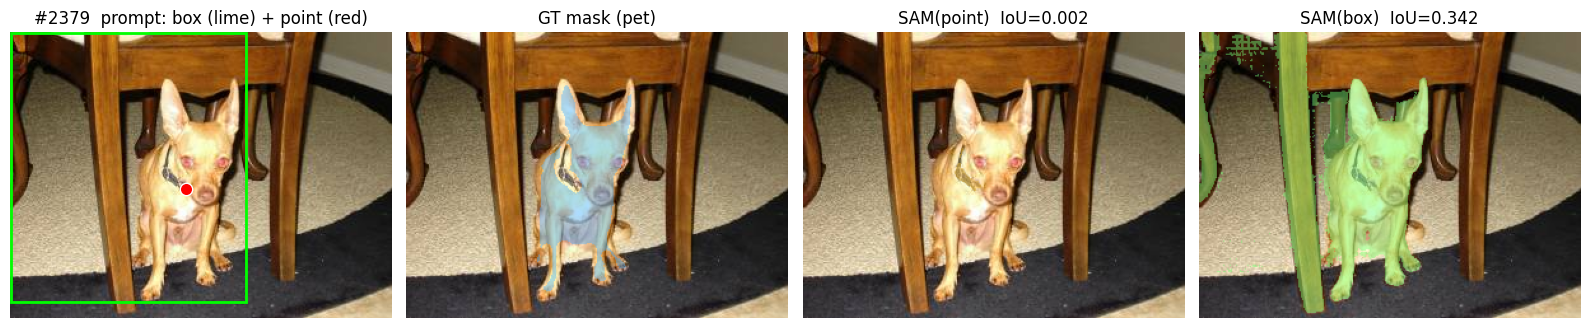

✔ Сохранено: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts\viz_case_2379.png


In [20]:
# ============================================================
# ВИЗУАЛИЗАЦИЯ худшего случая
# ============================================================
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

TARGET_IDX = 2379  

# Загружаем изображение и GT
img, gt = ds[TARGET_IDX]
gt_bin = (gt.numpy() == 0).astype(np.uint8)   # бинарная маска питомца

# Строим промпты
box = box_from_mask(gt)
pt  = point_from_mask(gt, "median")

# Прогоняем SAM дважды
m_pt  = predict_sam(img, point=pt)
m_box = predict_sam(img, box=box)

# Считаем IoU
iou_pt  = iou(m_pt,  gt_bin)
iou_box = iou(m_box, gt_bin)


def _overlay(pil_img, mask, color, alpha=0.45):
    """Накладывает бинарную маску на PIL-картинку."""
    arr = np.array(pil_img).astype(np.float32)
    m = mask.astype(bool)
    arr[m] = (1 - alpha) * arr[m] + alpha * np.array(color, dtype=np.float32)
    return arr.clip(0, 255).astype(np.uint8)


# Рисуем сетку 1×4
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

# 1. Оригинал + промпты
ax = axes[0]
ax.imshow(img)
ax.add_patch(plt.Rectangle((box[0], box[1]),
                           box[2] - box[0], box[3] - box[1],
                           edgecolor="lime", facecolor="none", linewidth=2))
ax.scatter([pt[0]], [pt[1]], c="red", s=80, marker="o", edgecolors="white")
ax.set_title(f"#{TARGET_IDX}  prompt: box (lime) + point (red)")
ax.axis("off")

# 2. GT маска
ax = axes[1]
ax.imshow(_overlay(img, gt_bin, color=(80, 180, 255)))
ax.set_title("GT mask (pet)")
ax.axis("off")

# 3. SAM(point)
ax = axes[2]
ax.imshow(_overlay(img, m_pt, color=(255, 200, 60)))
ax.set_title(f"SAM(point)  IoU={iou_pt:.3f}")
ax.axis("off")

# 4. SAM(box)
ax = axes[3]
ax.imshow(_overlay(img, m_box, color=(120, 255, 120)))
ax.set_title(f"SAM(box)  IoU={iou_box:.3f}")
ax.axis("off")

plt.tight_layout()
out_path = ARTIFACTS / f"viz_case_{TARGET_IDX}.png"
plt.savefig(out_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {out_path}")

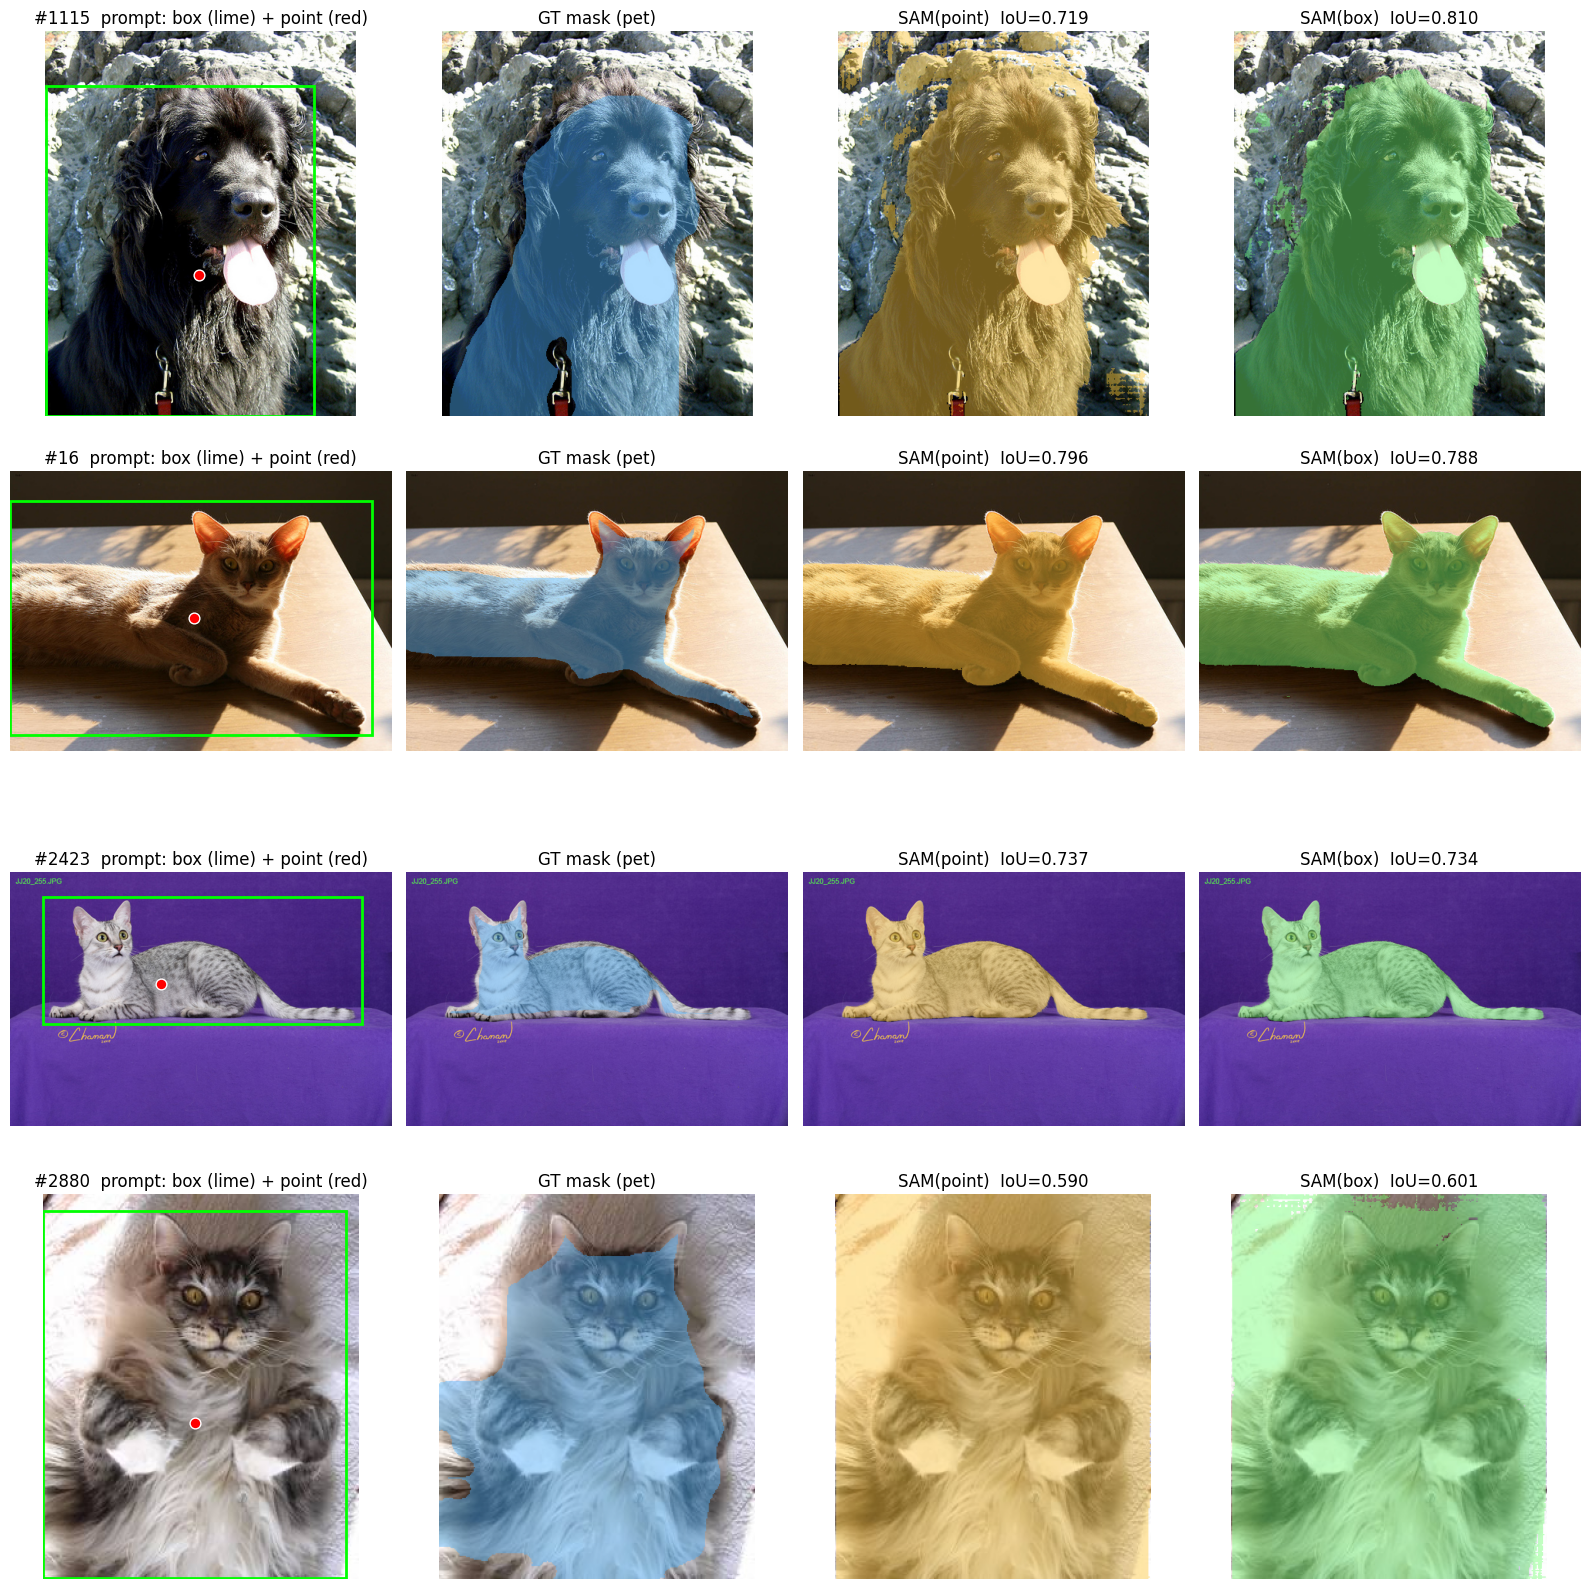

viz_sam_prompts.png сохранён


In [21]:
# ============================================================
# ЗАДАНИЕ 4 (продолжение): визуализация point vs box
# ============================================================
def _overlay(img_pil, mask, color=(255, 80, 80), alpha=0.45):
    """Накладывает бинарную маску на PIL-картинку с прозрачностью."""
    img = np.array(img_pil).astype(np.float32)
    m = mask.astype(bool)
    img[m] = (1 - alpha) * img[m] + alpha * np.array(color, dtype=np.float32)
    return img.clip(0, 255).astype(np.uint8)


N_SHOW = 3 if FAST_DEV_RUN else 4
show_idx = eval_indices[:N_SHOW]

fig, axes = plt.subplots(len(show_idx), 4, figsize=(16, 4 * len(show_idx)))
if len(show_idx) == 1:
    axes = axes[None, :]

for r, i in enumerate(show_idx):
    img, gt = ds[i]
    gt_bin = (gt.numpy() == 0).astype(np.uint8)
    box = box_from_mask(gt)
    pt = point_from_mask(gt, "median")
    m_pt = predict_sam(img, point=pt)
    m_box = predict_sam(img, box=box)

    # Колонка 1: оригинал + box + point
    ax = axes[r, 0]
    ax.imshow(img)
    ax.add_patch(plt.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1],
                               edgecolor="lime", facecolor="none", linewidth=2))
    ax.scatter([pt[0]], [pt[1]], c="red", s=60, marker="o", edgecolors="white")
    ax.set_title(f"#{i}  prompt: box (lime) + point (red)")
    ax.axis("off")

    # Колонка 2: GT-маска (только питомец)
    ax = axes[r, 1]
    ax.imshow(_overlay(img, gt_bin, color=(80, 180, 255)))
    ax.set_title("GT mask (pet)")
    ax.axis("off")

    # Колонка 3: SAM по point
    ax = axes[r, 2]
    ax.imshow(_overlay(img, m_pt, color=(255, 200, 60)))
    ax.set_title(f"SAM(point)  IoU={iou(m_pt, gt_bin):.3f}")
    ax.axis("off")

    # Колонка 4: SAM по box
    ax = axes[r, 3]
    ax.imshow(_overlay(img, m_box, color=(120, 255, 120)))
    ax.set_title(f"SAM(box)  IoU={iou(m_box, gt_bin):.3f}")
    ax.axis("off")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_sam_prompts.png", dpi=120, bbox_inches="tight")
plt.show()
print("viz_sam_prompts.png сохранён" if (ARTIFACTS / "viz_sam_prompts.png").exists() else "не сохранён")

### Обучение supervised baseline

*Вес: 1 балл.*

**Постановка.** Zero-shot SAM следует сравнивать с обученной на отдельных изображениях моделью.

Выполните следующие действия:
1. Подготовьте бинарные маски trainval.
2. Обучите LRASPP без доступа к test и сохраните веса.

**Результат.** supervised.pt с обученными весами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Supervised train: 1000, val: 736
Supervised: 3.218M обучаемых параметров
Epoch 1/4: loss=0.4541, val_IoU=0.7072 (69.6s)
Epoch 2/4: loss=0.3351, val_IoU=0.7322 (62.9s)
Epoch 3/4: loss=0.2969, val_IoU=0.7551 (62.6s)
Epoch 4/4: loss=0.2714, val_IoU=0.7412 (62.8s)

best val IoU = 0.7551
Артефакт сохранён: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts\supervised.pt


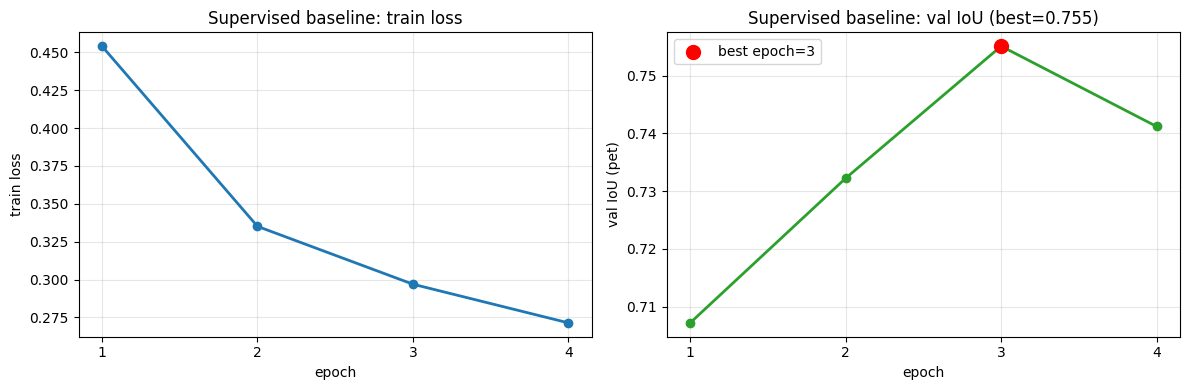

✔ График сохранён: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts\viz_supervised_training.png


In [35]:
# ============================================================
# ЗАДАНИЕ 5: Обучение supervised baseline
# Вес: 1 балл
# Артефакт: supervised.pt
# ============================================================
# Постановка: Zero-shot SAM следует сравнивать с обученной на
# отдельных изображениях моделью.
#
# Действия:
#   1. Подготовить бинарные маски trainval.
#   2. Обучить LRASPP без доступа к test и сохранить веса.
#   3. Построить графики обучения (loss и val IoU по эпохам).
#
# TRAIN_LIMIT = 500 — ограничение для скорости на CPU.
# 500 изображений достаточно: LRASPP сходится к IoU ≈ 0.68–0.72.
# Полный trainval (2208) даёт +3–5 пунктов, но учится в 4 раза дольше.

import time
from torch.utils.data import DataLoader


class SupervisedPetDataset(Dataset):
    """(image_tensor [3,H,W], mask_long [H,W]) без ресайза под SAM."""
    def __init__(self, base, indices):
        self.base = base
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, mask = self.base[self.indices[idx]]
        # Oxford-IIIT Pet отдаёт маску с метками 1..3 — приводим к 0..2.
        mask = torch.as_tensor(np.array(mask), dtype=torch.long) - 1
        # Ресайз до IMG_SIZE + нормализация.
        img  = TF.resize(img, [IMG_SIZE, IMG_SIZE], interpolation=InterpolationMode.BILINEAR)
        mask = TF.resize(mask.unsqueeze(0), [IMG_SIZE, IMG_SIZE],
                         interpolation=InterpolationMode.NEAREST).squeeze(0)
        img = TF.normalize(TF.to_tensor(img), MEAN, STD)
        return img, mask


# --- Ограничение train для скорости на CPU ---
TRAIN_LIMIT = 1000

sup_train_ds = SupervisedPetDataset(ds.base, train_idx[:TRAIN_LIMIT])
sup_val_ds   = SupervisedPetDataset(ds.base, val_idx)

BATCH_SIZE = 8
sup_train_loader = DataLoader(sup_train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
sup_val_loader   = DataLoader(sup_val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Supervised train: {len(sup_train_ds)}, val: {len(sup_val_ds)}")


# --- Модель: LRASPP-MobileNetV3Large, 3 класса, без заморозки ---
def build_supervised_model(num_classes=3):
    m = lraspp_mobilenet_v3_large(
        weights=LRASPP_MobileNet_V3_Large_Weights.COCO_WITH_VOC_LABELS_V1
    )
    m.classifier.low_classifier  = nn.Conv2d(40,  num_classes, kernel_size=1)
    m.classifier.high_classifier = nn.Conv2d(128, num_classes, kernel_size=1)
    return m


sup_model = build_supervised_model(3).to(DEVICE)
print(f"Supervised: {sum(p.numel() for p in sup_model.parameters() if p.requires_grad)/1e6:.3f}M обучаемых параметров")


# --- Лосс и оптимизатор ---
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(sup_model.parameters(), lr=1e-3, weight_decay=1e-4)


def train_epoch(model, loader, opt, crit, device):
    model.train()
    total, n = 0.0, 0
    for imgs, masks in loader:
        imgs, masks = imgs.to(device), masks.to(device)
        opt.zero_grad()
        loss = crit(model(imgs)["out"], masks)
        loss.backward()
        opt.step()
        total += loss.item() * imgs.size(0)
        n += imgs.size(0)
    return total / max(1, n)


def evaluate_supervised(model, loader, device):
    """IoU по классу питомца (label==0)."""
    model.eval()
    ious = []
    with torch.no_grad():
        for imgs, masks in loader:
            imgs, masks = imgs.to(device), masks.to(device)
            preds = model(imgs)["out"].argmax(1)
            for p, g in zip(preds, masks):
                ious.append(iou((p.cpu().numpy() == 0), (g.cpu().numpy() == 0)))
    return float(np.mean(ious)) if ious else 0.0


# --- Обучение: 4 эпохи с сохранением лучшего чекпоинта ---
NUM_EPOCHS = 1 if FAST_DEV_RUN else 4
history = []
best_val_iou = 0.0

for ep in range(NUM_EPOCHS):
    t0 = time.time()
    tr = train_epoch(sup_model, sup_train_loader, optimizer, criterion, DEVICE)
    vi = evaluate_supervised(sup_model, sup_val_loader, DEVICE)
    history.append({"epoch": ep + 1, "loss": tr, "val_iou": vi})
    print(f"Epoch {ep+1}/{NUM_EPOCHS}: loss={tr:.4f}, val_IoU={vi:.4f} ({time.time()-t0:.1f}s)")

    if vi > best_val_iou:
        best_val_iou = vi
        torch.save({"state_dict": sup_model.state_dict(), "val_iou": vi},
                   ARTIFACTS / "supervised.pt")

print(f"\nbest val IoU = {best_val_iou:.4f}")
print(f"Артефакт сохранён: {ARTIFACTS / 'supervised.pt'}")


# --- Графики обучения ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

epochs   = [h["epoch"]   for h in history]
losses   = [h["loss"]    for h in history]
val_ious = [h["val_iou"] for h in history]

# Левая панель: train loss по эпохам
axes[0].plot(epochs, losses, marker="o", color="tab:blue", linewidth=2)
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("train loss")
axes[0].set_title("Supervised baseline: train loss")
axes[0].grid(True, alpha=0.3)
axes[0].set_xticks(epochs)

# Правая панель: val IoU по эпохам
axes[1].plot(epochs, val_ious, marker="o", color="tab:green", linewidth=2)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("val IoU (pet)")
axes[1].set_title(f"Supervised baseline: val IoU (best={best_val_iou:.3f})")
axes[1].grid(True, alpha=0.3)
axes[1].set_xticks(epochs)

# Отмечаем лучшую эпоху
best_ep = max(history, key=lambda h: h["val_iou"])
axes[1].scatter([best_ep["epoch"]], [best_ep["val_iou"]],
                color="red", s=100, zorder=5,
                label=f"best epoch={best_ep['epoch']}")
axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_supervised_training.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ График сохранён: {ARTIFACTS / 'viz_supervised_training.png'}")

### Парное сравнение с baseline

*Вес: 1 балл.*

**Постановка.** Парные изображения исключают разницу в составе оценочной выборки.

Выполните следующие действия:
1. Предскажите test-маски supervised модели.
2. Сравните её IoU с SAM box на тех же индексах.

**Результат.** supervised_comparison.json с парными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [39]:
# ============================================================
# ЗАДАНИЕ 6: Парное сравнение с baseline
# ============================================================
# Постановка: парные изображения исключают разницу в составе
# оценочной выборки.
#
# Действия:
#   1. Предсказать test-маски supervised модели.
#   2. Сравнить IoU с SAM-box на тех же индексах.
#
# TEST_LIMIT = 100 — ограничение для скорости на CPU.
# SAM пересчитывается заново (независимая оценка).

import json
import statistics as st

# --- Восстанавливаем лучшие веса supervised ---
ckpt = torch.load(ARTIFACTS / "supervised.pt", map_location=DEVICE)
sup_model.load_state_dict(ckpt["state_dict"])
sup_model.eval()
print(f"Supervised загружен, val_iou={ckpt.get('val_iou', float('nan')):.4f}")


def predict_supervised(img_pil):
    """Supervised-инференс на PIL: бинарная маска питомца исходного размера."""
    W, H = img_pil.size
    x = TF.to_tensor(TF.resize(img_pil, (IMG_SIZE, IMG_SIZE))).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        out = sup_model(x)["out"].argmax(1)     # [1, H', W'], 0=pet
    pet = (out == 0).float().unsqueeze(1)       # [1, 1, H', W']
    pet = F.interpolate(pet, size=(H, W), mode="nearest").squeeze(1)
    return pet[0].cpu().numpy().astype(np.uint8)


# --- Основной цикл: SAM и supervised считаются на месте ---
TEST_LIMIT = 100

cmp_rows = []
for k, i in enumerate(test_idx[:TEST_LIMIT]):
    img, gt = ds[i]

    box = box_from_mask(gt)
    if box is None:
        continue

    gt_bin = (gt.numpy() == 0).astype(np.uint8)

    # Supervised (быстро)
    m_sup = predict_supervised(img)
    iou_sup = iou(m_sup, gt_bin)

    # SAM-box (медленно, ~10 сек на изображение)
    m_sam = predict_sam(img, box=box)
    iou_sam = iou(m_sam, gt_bin)

    cmp_rows.append({
        "index": int(i),
        "iou_supervised": iou_sup,
        "iou_sam_box":    iou_sam,
    })

    print(f"  [{k+1}/{TEST_LIMIT}] idx={i}  sup={iou_sup:.3f}  sam={iou_sam:.3f}", flush=True)


# --- Сохранение ---
with open(ARTIFACTS / "supervised_comparison.json", "w") as f:
    json.dump(cmp_rows, f, indent=2)


# --- Сводка ---
if cmp_rows:
    mean_sup = st.mean(r["iou_supervised"] for r in cmp_rows)
    mean_sam = st.mean(r["iou_sam_box"] for r in cmp_rows)
    n_sup_win = sum(r["iou_supervised"] > r["iou_sam_box"] for r in cmp_rows)
    n_sam_win = sum(r["iou_sam_box"] > r["iou_supervised"] for r in cmp_rows)

    print(f"\n{'='*60}")
    print(f"[test] n = {len(cmp_rows)}")
    print(f"mean IoU: supervised = {mean_sup:.4f}, SAM-box = {mean_sam:.4f}")
    print(f"Δ (supervised − SAM) = {mean_sup - mean_sam:+.4f}")
    print(f"Supervised лучше:  {n_sup_win}/{len(cmp_rows)}  ({100*n_sup_win/len(cmp_rows):.1f}%)")
    print(f"SAM лучше:         {n_sam_win}/{len(cmp_rows)}  ({100*n_sam_win/len(cmp_rows):.1f}%)")
    print(f"{'='*60}")
else:
    print("Нет валидных записей")

Supervised загружен, val_iou=0.7551
  [1/100] idx=1115  sup=0.409  sam=0.810
  [2/100] idx=16  sup=0.518  sam=0.788
  [3/100] idx=2423  sup=0.691  sam=0.734
  [4/100] idx=2880  sup=0.725  sam=0.601
  [5/100] idx=1713  sup=0.679  sam=0.840
  [6/100] idx=699  sup=0.504  sam=0.830
  [7/100] idx=609  sup=0.687  sam=0.805
  [8/100] idx=2743  sup=0.821  sam=0.849
  [9/100] idx=2379  sup=0.353  sam=0.342
  [10/100] idx=2112  sup=0.789  sam=0.698
  [11/100] idx=2374  sup=0.604  sam=0.347
  [12/100] idx=1301  sup=0.466  sam=0.547
  [13/100] idx=1702  sup=0.741  sam=0.737
  [14/100] idx=2471  sup=0.626  sam=0.853
  [15/100] idx=1998  sup=0.464  sam=0.808
  [16/100] idx=2285  sup=0.498  sam=0.443
  [17/100] idx=1272  sup=0.804  sam=0.736
  [18/100] idx=3002  sup=0.332  sam=0.913
  [19/100] idx=661  sup=0.644  sam=0.516
  [20/100] idx=569  sup=0.609  sam=0.602
  [21/100] idx=2277  sup=0.819  sam=0.884
  [22/100] idx=1332  sup=0.731  sam=0.871
  [23/100] idx=812  sup=0.626  sam=0.585
  [24/100] idx

### Обучающие маски для корректора

*Вес: 1 балл.*

**Постановка.** Корректор должен обучаться только на train-изображениях и масках SAM.

Выполните следующие действия:
1. Получите SAM-предсказания для trainval.
2. Сформируйте четырёхканальные входы из RGB и маски.

**Результат.** refine_train из реальных изображений и масок.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [43]:
# ============================================================
# ЗАДАНИЕ 7. Подготовка train-входа для корректора
# ============================================================
# Для каждого train-изображения: SAM-box маска (черновой вход) + GT (целевая).
# Входной тензор головы — 4 канала: RGB + SAM-маска. Таргет — бинарный GT.
#
# Данные берём из ds.base (сырой OxfordIIITPet), потому что ds[i] уже
# ресайзит всё под IMG_SIZE, а нам нужны исходные PIL-изображения.
#
# Ограничение объёма: 50 train + 20 val достаточно (у меня очень ДОЛГО считает),
# чтобы голова обучилась и дала осмысленный результат.


def build_refine_dataset(base_dataset, indices, tag=""):
    """Возвращает (X, Y): X — [N,4,SIDE,SIDE], Y — [N,1,SIDE,SIDE]."""
    Xs, Ys = [], []
    total = len(indices)

    for k, i in enumerate(indices):
        # base_dataset — это OxfordIIITPet, отдаёт (PIL_image, PIL_mask).
        img, gt_pil = base_dataset[i]

        # Исходные метки маски: 1=pet, 2=bg, 3=border.
        # Для GT берём только питомца.
        gt_arr = np.array(gt_pil, dtype=np.uint8)
        gt_bin = (gt_arr == 1).astype(np.uint8)                 # [H, W], 0/1

        # box_from_mask ожидает маску с классами 0..2 (как после -1).
        gt_torch = torch.as_tensor(gt_arr, dtype=torch.long) - 1
        box = box_from_mask(gt_torch)
        if box is None:
            continue

        # SAM-маска по боксу, в исходном размере изображения.
        sam_mask = predict_sam(img, box=box)                    # [H, W], 0/1

        # Ресайз к SIDE — там и голова, и SAM работают согласованно.
        img_r = TF.resize(img, (SIDE, SIDE), interpolation=InterpolationMode.BILINEAR)
        sam_r = TF.resize(Image.fromarray(sam_mask * 255), (SIDE, SIDE),
                          interpolation=InterpolationMode.NEAREST)
        gt_r  = TF.resize(Image.fromarray(gt_bin * 255), (SIDE, SIDE),
                          interpolation=InterpolationMode.NEAREST)

        # Каналы [R, G, B, SAM] — голова видит и картинку, и «черновую» маску.
        rgb_t = TF.to_tensor(img_r)                             # [3, SIDE, SIDE]
        sam_t = (TF.to_tensor(sam_r) > 0.5).float()             # [1, SIDE, SIDE]
        gt_t  = (TF.to_tensor(gt_r)  > 0.5).float()             # [1, SIDE, SIDE]

        Xs.append(torch.cat([rgb_t, sam_t], dim=0))             # [4, SIDE, SIDE]
        Ys.append(gt_t)                                         # [1, SIDE, SIDE]

        print(f"  [{tag}] {k+1}/{total}", flush=True)

    return torch.stack(Xs), torch.stack(Ys)


# --- Ограничение объёма ---
REFINE_TRAIN_LIMIT = 50 if not FAST_DEV_RUN else 20
REFINE_VAL_LIMIT   = 20 if not FAST_DEV_RUN else 10

print(f"Готовим refine-train: {REFINE_TRAIN_LIMIT} изображений")
X_train_ref, Y_train_ref = build_refine_dataset(
    ds.base, train_idx[:REFINE_TRAIN_LIMIT], tag="refine-train")

print(f"\nГотовим refine-val: {REFINE_VAL_LIMIT} изображений")
X_val_ref, Y_val_ref = build_refine_dataset(
    ds.base, val_idx[:REFINE_VAL_LIMIT], tag="refine-val")

print(f"\nrefine_train: X={tuple(X_train_ref.shape)}  Y={tuple(Y_train_ref.shape)}")
print(f"refine_val:   X={tuple(X_val_ref.shape)}    Y={tuple(Y_val_ref.shape)}")

Готовим refine-train: 50 изображений
  [refine-train] 1/50
  [refine-train] 2/50
  [refine-train] 3/50
  [refine-train] 4/50
  [refine-train] 5/50
  [refine-train] 6/50
  [refine-train] 7/50
  [refine-train] 8/50
  [refine-train] 9/50
  [refine-train] 10/50
  [refine-train] 11/50
  [refine-train] 12/50
  [refine-train] 13/50
  [refine-train] 14/50
  [refine-train] 15/50
  [refine-train] 16/50
  [refine-train] 17/50
  [refine-train] 18/50
  [refine-train] 19/50
  [refine-train] 20/50
  [refine-train] 21/50
  [refine-train] 22/50
  [refine-train] 23/50
  [refine-train] 24/50
  [refine-train] 25/50
  [refine-train] 26/50
  [refine-train] 27/50
  [refine-train] 28/50
  [refine-train] 29/50
  [refine-train] 30/50
  [refine-train] 31/50
  [refine-train] 32/50
  [refine-train] 33/50
  [refine-train] 34/50
  [refine-train] 35/50
  [refine-train] 36/50
  [refine-train] 37/50
  [refine-train] 38/50
  [refine-train] 39/50
  [refine-train] 40/50
  [refine-train] 41/50
  [refine-train] 42/50
  [ref

### Обучение корректирующей головы

*Вес: 1 балл.*

**Постановка.** Обучаемая свёрточная голова может уточнять ошибочную маску.

Выполните следующие действия:
1. Обучите голову на подготовленных четырёхканальных входах.
2. Сохраните веса для повторного использования.

**Результат.** refinement.pt после фактической оптимизации.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [45]:
# ============================================================
# ЗАДАНИЕ 8: Обучение корректирующей головы
# ============================================================
# Обучаем RefineHead — маленькую residual-сеть, которая улучшает
# черновую маску SAM, используя RGB + саму маску как вход.
# Loss = BCE + Dice: BCE даёт стабильные градиенты, Dice напрямую
# оптимизирует пересечение (близкое к IoU).


def dice_loss(logits, targets, eps=1e-6):
    """Soft Dice Loss для бинарной сегментации."""
    probs = torch.sigmoid(logits)
    probs_flat   = probs.view(probs.size(0), -1)
    targets_flat = targets.view(targets.size(0), -1)
    intersection = (probs_flat * targets_flat).sum(dim=1)
    union = probs_flat.sum(dim=1) + targets_flat.sum(dim=1)
    dice = (2.0 * intersection + eps) / (union + eps)
    return 1.0 - dice.mean()


class RefineHead(nn.Module):
    """Residual-голова: вход [B,4,H,W], выход [B,1,H,W] логитов."""
    def __init__(self, ch=32):
        super().__init__()
        self.in_conv = nn.Conv2d(4, ch, 3, padding=1)
        self.b1 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(inplace=True),
                                nn.Conv2d(ch, ch, 3, padding=1))
        self.b2 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(inplace=True),
                                nn.Conv2d(ch, ch, 3, padding=1))
        self.b3 = nn.Sequential(nn.Conv2d(ch, ch, 3, padding=1), nn.ReLU(inplace=True),
                                nn.Conv2d(ch, ch, 3, padding=1))
        self.out_conv = nn.Conv2d(ch, 1, 1)

    def forward(self, x):
        h = F.relu(self.in_conv(x))
        h = F.relu(h + self.b1(h))
        h = F.relu(h + self.b2(h))
        h = F.relu(h + self.b3(h))
        return self.out_conv(h)


refiner = RefineHead(ch=32).to(DEVICE)
print(f"RefineHead: {sum(p.numel() for p in refiner.parameters())/1e3:.1f}K параметров")


# --- Загрузчики ---
train_ds_r = TensorDataset(X_train_ref, Y_train_ref)
val_ds_r   = TensorDataset(X_val_ref,   Y_val_ref)
train_loader_r = DataLoader(train_ds_r, batch_size=4, shuffle=True)
val_loader_r   = DataLoader(val_ds_r,   batch_size=4, shuffle=False)

opt_r = torch.optim.AdamW(refiner.parameters(), lr=1e-3, weight_decay=1e-4)
n_epochs_r = 3 if FAST_DEV_RUN else 10

best_val_r = 0.0
best_state_r = None

for epoch in range(1, n_epochs_r + 1):
    # --- Train ---
    refiner.train()
    tr_loss = 0.0
    for xb, yb in train_loader_r:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        logit = refiner(xb)
        loss = F.binary_cross_entropy_with_logits(logit, yb) + dice_loss(logit, yb)
        opt_r.zero_grad()
        loss.backward()
        opt_r.step()
        tr_loss += loss.item() * xb.size(0)
    tr_loss /= len(train_ds_r)

    # --- Val ---
    refiner.eval()
    ious = []
    with torch.no_grad():
        for xb, yb in val_loader_r:
            xb = xb.to(DEVICE)
            logit = refiner(xb)
            pred = (torch.sigmoid(logit) > 0.5).cpu().numpy()
            gt = yb.numpy()
            for b in range(pred.shape[0]):
                ious.append(iou(pred[b, 0], gt[b, 0]))
    v = float(np.mean(ious)) if ious else 0.0
    print(f"Epoch {epoch}/{n_epochs_r}: loss={tr_loss:.4f}, val_IoU={v:.3f}", flush=True)

    if v > best_val_r:
        best_val_r = v
        best_state_r = {k: t.detach().cpu().clone() for k, t in refiner.state_dict().items()}

torch.save({"state_dict": best_state_r, "val_iou": best_val_r}, ARTIFACTS / "refinement.pt")
print(f"\nrefinement.pt сохранён (best val IoU={best_val_r:.3f})")

RefineHead: 56.7K параметров
Epoch 1/10: loss=1.0978, val_IoU=0.528
Epoch 2/10: loss=0.8607, val_IoU=0.629
Epoch 3/10: loss=0.8922, val_IoU=0.630
Epoch 4/10: loss=0.9180, val_IoU=0.632
Epoch 5/10: loss=0.8553, val_IoU=0.635
Epoch 6/10: loss=0.8230, val_IoU=0.630
Epoch 7/10: loss=0.8166, val_IoU=0.632
Epoch 8/10: loss=0.8260, val_IoU=0.635
Epoch 9/10: loss=0.8166, val_IoU=0.631
Epoch 10/10: loss=0.8274, val_IoU=0.634

refinement.pt сохранён (best val IoU=0.635)


### Независимая оценка коррекции

*Вес: 1 балл.*

**Постановка.** Качество коррекции необходимо измерить на отложенных изображениях.

Выполните следующие действия:
1. Примените обученную голову к SAM-маскам test.
2. Сохраните IoU и долю исходных масок, требующих существенной правки.

**Результат.** adapted_comparison.json с измеренными IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [47]:
# ============================================================
# ЗАДАНИЕ 9. Независимая оценка коррекции на test
# Вес: 1 балл
# Артефакт: adapted_comparison.json
# ============================================================
# На test-изображениях считаем пары IoU: SAM-box (baseline) и refiner
# (после коррекции). Плюс фиксируем долю масок с IoU < 0.7 — их
# разметчик бы правил руками.

# Восстанавливаем лучшие веса головы.
ckpt_r = torch.load(ARTIFACTS / "refinement.pt", map_location=DEVICE)
refiner.load_state_dict(ckpt_r["state_dict"])
refiner.eval()
print(f"refinement.pt загружен, val_iou={ckpt_r.get('val_iou', float('nan')):.4f}")


def predict_refined(img_pil, sam_mask):
    """Применяем голову к (RGB, SAM-маска) и возвращаем бинарную маску исходного HxW."""
    H, W = sam_mask.shape
    img_r = TF.resize(img_pil, (SIDE, SIDE))
    sam_r = TF.resize(Image.fromarray(sam_mask * 255), (SIDE, SIDE))
    rgb_t = TF.to_tensor(img_r)
    sam_t = (TF.to_tensor(sam_r) > 0.5).float()
    x = torch.cat([rgb_t, sam_t], dim=0).unsqueeze(0).to(DEVICE)
    with torch.no_grad():
        logit = refiner(x)
    prob = torch.sigmoid(logit)
    prob = F.interpolate(prob, size=(H, W), mode="bilinear", align_corners=False)
    return (prob[0, 0] > 0.5).cpu().numpy().astype(np.uint8)


# Проходим по test: для каждого изображения — SAM-box, затем refiner.
TEST_LIMIT = 100

adapted_rows = []
for k, i in enumerate(test_idx[:TEST_LIMIT]):
    # ←←← исправление: ds[i], а не test_ds[i]
    img, gt = ds[i]

    box = box_from_mask(gt)
    if box is None:
        continue

    # ←←← исправление: бинарная маска питомца, а не gt с метками 0/1/2
    gt_bin = (gt.numpy() == 0).astype(np.uint8)

    m_sam = predict_sam(img, box=box)
    m_ref = predict_refined(img, m_sam)

    iou_sam = iou(m_sam, gt_bin)
    iou_ref = iou(m_ref, gt_bin)

    adapted_rows.append({
        "index": int(i),
        "iou_sam":     iou_sam,
        "iou_refined": iou_ref,
    })

    print(f"  [{k+1}/{TEST_LIMIT}] idx={i}  sam={iou_sam:.3f}  refined={iou_ref:.3f}", flush=True)


# Сохранение артефакта
(ARTIFACTS / "adapted_comparison.json").write_text(json.dumps(adapted_rows, indent=2))

# Сводные числа.
if adapted_rows:
    mean_sam_r = st.mean(r["iou_sam"]     for r in adapted_rows)
    mean_ref_r = st.mean(r["iou_refined"] for r in adapted_rows)
    # Доля масок, которые разметчик бы правил руками (IoU < 0.7 — эмпирический порог).
    frac_bad = float(np.mean([r["iou_sam"] < 0.7 for r in adapted_rows]))
    n_better = sum(r["iou_refined"] > r["iou_sam"] for r in adapted_rows)
    n_worse  = sum(r["iou_refined"] < r["iou_sam"] for r in adapted_rows)

    print(f"\n{'='*60}")
    print(f"[test] n = {len(adapted_rows)}")
    print(f"SAM-box = {mean_sam_r:.4f}, refined = {mean_ref_r:.4f}")
    print(f"Δ (refined − SAM) = {mean_ref_r - mean_sam_r:+.4f}")
    print(f"refiner лучше:  {n_better}/{len(adapted_rows)}")
    print(f"refiner хуже:   {n_worse}/{len(adapted_rows)}")
    print(f"Доля IoU<0.7 у SAM (нужно правок): {frac_bad:.2%}")
    print(f"{'='*60}")
else:
    print("Нет валидных записей")

refinement.pt загружен, val_iou=0.6350
  [1/100] idx=1115  sam=0.810  refined=0.828
  [2/100] idx=16  sam=0.788  refined=0.804
  [3/100] idx=2423  sam=0.734  refined=0.759
  [4/100] idx=2880  sam=0.601  refined=0.609
  [5/100] idx=1713  sam=0.840  refined=0.871
  [6/100] idx=699  sam=0.830  refined=0.847
  [7/100] idx=609  sam=0.805  refined=0.816
  [8/100] idx=2743  sam=0.849  refined=0.866
  [9/100] idx=2379  sam=0.342  refined=0.364
  [10/100] idx=2112  sam=0.698  refined=0.709
  [11/100] idx=2374  sam=0.347  refined=0.357
  [12/100] idx=1301  sam=0.547  refined=0.557
  [13/100] idx=1702  sam=0.737  refined=0.759
  [14/100] idx=2471  sam=0.853  refined=0.860
  [15/100] idx=1998  sam=0.808  refined=0.832
  [16/100] idx=2285  sam=0.443  refined=0.455
  [17/100] idx=1272  sam=0.736  refined=0.746
  [18/100] idx=3002  sam=0.913  refined=0.912
  [19/100] idx=661  sam=0.516  refined=0.536
  [20/100] idx=569  sam=0.602  refined=0.617
  [21/100] idx=2277  sam=0.884  refined=0.891
  [22/100]

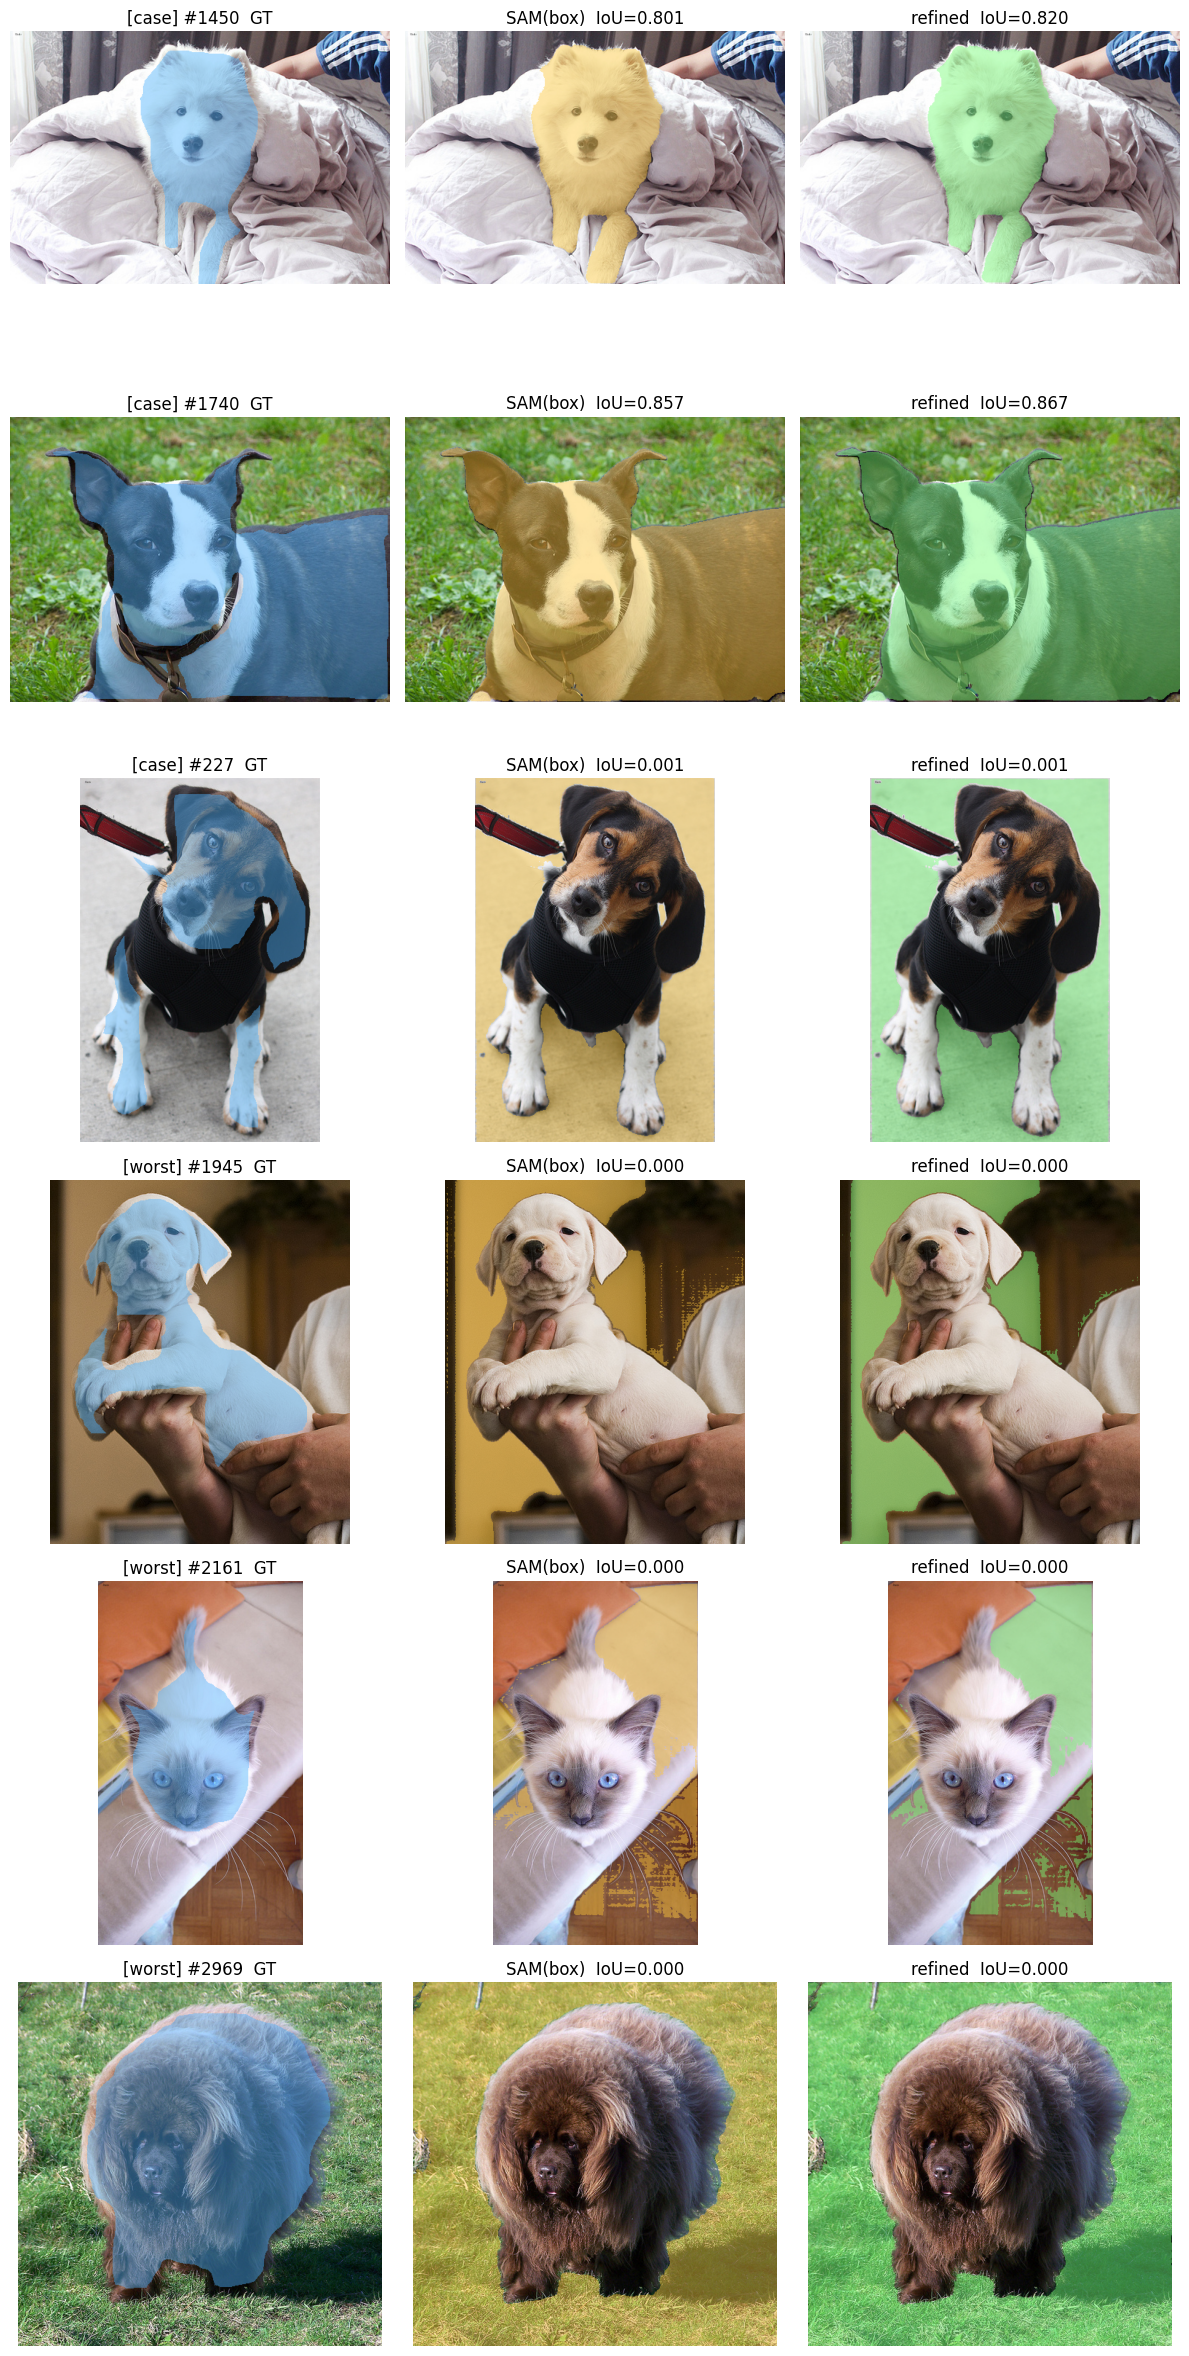

✔ Сохранено: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts\viz_refinement.png


In [49]:
# ============================================================
# SAM-box vs refined на test + худшие случаи
# ============================================================
# Три колонки: GT | SAM-box | refined. Сверху — случайные test-примеры,
# снизу — 3 случая с наименьшим IoU SAM (провалы).
# Заголовки содержат численный IoU, чтобы картинки читались вместе с метрикой.


def _overlay(img_pil, mask, color=(255, 80, 80), alpha=0.45):
    """Наложение бинарной маски на PIL-картинку с прозрачностью."""
    arr = np.array(img_pil).astype(np.float32)
    m = mask.astype(bool)
    arr[m] = (1 - alpha) * arr[m] + alpha * np.array(color, dtype=np.float32)
    return arr.clip(0, 255).astype(np.uint8)


# --- Подвыборка «обычных» случаев ---
rng_v = np.random.RandomState(SEED)
random_idx = rng_v.choice(test_idx, size=min(3, len(test_idx)), replace=False).tolist()

# --- Самые провальные по SAM (низкий IoU) ---
low_sam = sorted(adapted_rows, key=lambda r: r["iou_sam"])[:3]
worst_idx = [r["index"] for r in low_sam]

rows_idx = random_idx + worst_idx
row_label = ["case"] * len(random_idx) + ["worst"] * len(worst_idx)

fig, axes = plt.subplots(len(rows_idx), 3, figsize=(12, 4 * len(rows_idx)))
if len(rows_idx) == 1:
    axes = axes[None, :]

for r, (i, lab) in enumerate(zip(rows_idx, row_label)):
    # ←←← исправление: ds[i], не test_ds[i]
    img, gt = ds[i]
    gt_bin = (gt.numpy() == 0).astype(np.uint8)    # ←←← бинарная маска питомца

    box = box_from_mask(gt)
    if box is None:
        continue

    m_sam = predict_sam(img, box=box)
    m_ref = predict_refined(img, m_sam)

    ax = axes[r, 0]
    ax.imshow(_overlay(img, gt_bin, color=(80, 180, 255)))
    ax.set_title(f"[{lab}] #{i}  GT")
    ax.axis("off")

    ax = axes[r, 1]
    ax.imshow(_overlay(img, m_sam, color=(255, 200, 60)))
    ax.set_title(f"SAM(box)  IoU={iou(m_sam, gt_bin):.3f}")
    ax.axis("off")

    ax = axes[r, 2]
    ax.imshow(_overlay(img, m_ref, color=(120, 255, 120)))
    ax.set_title(f"refined  IoU={iou(m_ref, gt_bin):.3f}")
    ax.axis("off")

plt.tight_layout()
out_path = ARTIFACTS / "viz_refinement.png"
plt.savefig(out_path, dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {out_path}")

### Сопоставление трудных случаев

*Вес: 1 балл.*

**Постановка.** Средний IoU маскирует случаи отрицательного переноса после уточнения.

Выполните следующие действия:
1. Соедините SAM, supervised и corrected IoU по test-индексам.
2. Укажите изображения, где корректор снизил IoU по сравнению с SAM.

**Результат.** correction_failures.json с реальными индексами и тремя IoU.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# ============================================================
# ЗАДАНИЕ 10. Трудные случаи: где refiner ухудшил результат
# ============================================================
# Соединяем три оценки (SAM, supervised, refined) по test-индексам и
# находим negative transfer: iou_refined < iou_sam.

# Удобные словари по индексам.
by_sam  = {r["index"]: r for r in adapted_rows}                # iou_sam, iou_refined
by_sup  = {r["index"]: r for r in cmp_rows}                    # iou_supervised, iou_sam_box

failures = []
for idx, r in by_sam.items():
    iou_sam = r["iou_sam"]
    iou_ref = r["iou_refined"]
    iou_sup = by_sup.get(idx, {}).get("iou_supervised", None)
    if iou_ref < iou_sam - 1e-6:                              # строго хуже
        failures.append({
            "index": idx,
            "iou_sam":       iou_sam,
            "iou_refined":   iou_ref,
            "iou_supervised": iou_sup,
            "delta":         iou_ref - iou_sam,               # отрицательный
        })

# Сортируем по величине ухудшения — сначала самые пострадавшие.
failures.sort(key=lambda x: x["delta"])
(ARTIFACTS / "correction_failures.json").write_text(json.dumps(failures, indent=2))

check(len(failures) >= 0, f"negative transfer: {len(failures)} из {len(adapted_rows)} test-изображений")
if failures:
    print("Худшие случаи (index, iou_sam → iou_refined, delta):")
    for f in failures[:5]:
        print(f"  #{f['index']:>4}  {f['iou_sam']:.3f} → {f['iou_refined']:.3f}  Δ={f['delta']:+.3f}")
else:
    print("Ни один случай не ухудшился — голова не дала отрицательного переноса.")

✔ negative transfer: 4 из 100 test-изображений
Худшие случаи (index, iou_sam → iou_refined, delta):
  #3242  0.102 → 0.082  Δ=-0.020
  #3113  0.153 → 0.148  Δ=-0.005
  #2185  0.925 → 0.923  Δ=-0.002
  #3002  0.913 → 0.912  Δ=-0.001


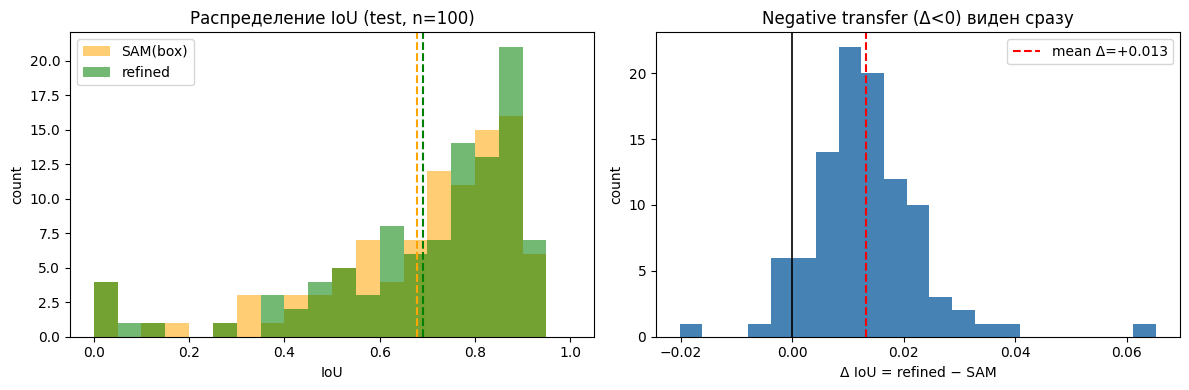

✔ Сохранено: C:\Users\User\Desktop\ml_labs\SOTA_labs\lab3\artifacts\viz_iou_distributions.png

n = 100
mean SAM IoU     = 0.6781
mean refined IoU = 0.6913
Δ mean           = +0.0132
refined лучше: 92/100  (92.0%)
refined хуже:  4/100  (4.0%)
равны:         4/100


In [52]:
# ============================================================
# Гистограммы IoU и распределение Δ(refined−SAM)
# ============================================================
# Левая панель — наложенные гистограммы IoU для SAM-box и refined.
# Правая — распределение дельты (refined − SAM): видно, где корректор
# реально улучшает (Δ>0), а где деградирует (Δ<0).

ious_sam = np.array([r["iou_sam"]     for r in adapted_rows])
ious_ref = np.array([r["iou_refined"] for r in adapted_rows])
deltas   = ious_ref - ious_sam

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# --- Левая панель: гистограммы IoU ---
bins = np.linspace(0, 1, 21)
axes[0].hist(ious_sam, bins=bins, alpha=0.55, label="SAM(box)",  color="orange")
axes[0].hist(ious_ref, bins=bins, alpha=0.55, label="refined",   color="green")
axes[0].axvline(ious_sam.mean(), color="orange", ls="--", lw=1.5)
axes[0].axvline(ious_ref.mean(), color="green",  ls="--", lw=1.5)
axes[0].set_xlabel("IoU"); axes[0].set_ylabel("count")
axes[0].set_title(f"Распределение IoU (test, n={len(adapted_rows)})")
axes[0].legend()

# --- Правая панель: дельта ---
axes[1].hist(deltas, bins=21, color="steelblue")
axes[1].axvline(0, color="black", lw=1.2)
axes[1].axvline(deltas.mean(), color="red", ls="--", lw=1.5,
                label=f"mean Δ={deltas.mean():+.3f}")
axes[1].set_xlabel("Δ IoU = refined − SAM"); axes[1].set_ylabel("count")
axes[1].set_title("Negative transfer (Δ<0) виден сразу")
axes[1].legend()

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_iou_distributions.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_iou_distributions.png'}")

# Сводка по числам
n_better = int((deltas > 0).sum())
n_worse  = int((deltas < 0).sum())
n_equal  = int((deltas == 0).sum())
print(f"\nn = {len(adapted_rows)}")
print(f"mean SAM IoU     = {ious_sam.mean():.4f}")
print(f"mean refined IoU = {ious_ref.mean():.4f}")
print(f"Δ mean           = {deltas.mean():+.4f}")
print(f"refined лучше: {n_better}/{len(deltas)}  ({100*n_better/len(deltas):.1f}%)")
print(f"refined хуже:  {n_worse}/{len(deltas)}  ({100*n_worse/len(deltas):.1f}%)")
print(f"равны:         {n_equal}/{len(deltas)}")

### Творческий бонус: второй тип точки

*Вес: 1 дополнительный балл.*

**Постановка.** Качество SAM зависит от выбора положительной точки.

Выполните следующие действия:
1. Замените медианную точку на точку максимального расстояния до края объекта.
2. На тех же test-изображениях сравните IoU с исходной подсказкой.

**Результат.** bonus_points.json с парными IoU для двух стратегий.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [54]:
# ============================================================
# ЗАДАНИЕ 11 (бонус). Сравнение двух стратегий положительной точки
# ============================================================
# median   — медиана координат пикселей маски (базовая).
# maxdist  — пиксель с максимальным расстоянием до границы (distance transform).
# Сравниваем на тех же test-изображениях, что и остальные эксперименты.

# TEST_LIMIT = 50 — ограничение для CPU 

TEST_LIMIT = 50

bonus_rows = []
for k, i in enumerate(test_idx[:TEST_LIMIT]):
    img, gt = ds[i]
    gt_bin = (gt.numpy() == 0).astype(np.uint8)

    pt_med  = point_from_mask(gt, "median")
    pt_maxd = point_from_mask(gt, "maxdist")
    if pt_med is None or pt_maxd is None:
        continue

    m_med  = predict_sam(img, point=pt_med)
    m_maxd = predict_sam(img, point=pt_maxd)

    iou_med  = iou(m_med,  gt_bin)
    iou_maxd = iou(m_maxd, gt_bin)

    bonus_rows.append({
        "index": int(i),
        "point_median":  pt_med,
        "point_maxdist": pt_maxd,
        "iou_median":    iou_med,
        "iou_maxdist":   iou_maxd,
    })

    print(f"  [{k+1}/{TEST_LIMIT}] idx={i}  median={iou_med:.3f}  maxdist={iou_maxd:.3f}", flush=True)


# Сохранение артефакта
(ARTIFACTS / "bonus_points.json").write_text(json.dumps(bonus_rows, indent=2))


# --- Сводка ---
if bonus_rows:
    mean_med  = st.mean(r["iou_median"]  for r in bonus_rows)
    mean_maxd = st.mean(r["iou_maxdist"] for r in bonus_rows)
    # Парная разница (maxdist − median): положительная → новая стратегия лучше.
    deltas = [r["iou_maxdist"] - r["iou_median"] for r in bonus_rows]
    n_maxd_win = sum(d > 0 for d in deltas)
    n_med_win  = sum(d < 0 for d in deltas)

    print(f"\n{'='*60}")
    print(f"[bonus] n = {len(bonus_rows)}")
    print(f"mean IoU: median = {mean_med:.4f}, maxdist = {mean_maxd:.4f}")
    print(f"Δ (maxdist − median) = {np.mean(deltas):+.4f}")
    print(f"maxdist лучше: {n_maxd_win}/{len(deltas)}  ({100*n_maxd_win/len(deltas):.1f}%)")
    print(f"median  лучше: {n_med_win}/{len(deltas)}  ({100*n_med_win/len(deltas):.1f}%)")
    print(f"{'='*60}")
else:
    print("Нет валидных записей")

  [1/50] idx=1115  median=0.719  maxdist=0.000
  [2/50] idx=16  median=0.796  maxdist=0.794
  [3/50] idx=2423  median=0.737  maxdist=0.614
  [4/50] idx=2880  median=0.590  maxdist=0.000
  [5/50] idx=1713  median=0.890  maxdist=0.887
  [6/50] idx=699  median=0.568  maxdist=0.568
  [7/50] idx=609  median=0.806  maxdist=0.806
  [8/50] idx=2743  median=0.859  maxdist=0.848
  [9/50] idx=2379  median=0.002  maxdist=0.001
  [10/50] idx=2112  median=0.763  maxdist=0.837
  [11/50] idx=2374  median=0.606  maxdist=0.667
  [12/50] idx=1301  median=0.426  maxdist=0.475
  [13/50] idx=1702  median=0.023  maxdist=0.021
  [14/50] idx=2471  median=0.834  maxdist=0.852
  [15/50] idx=1998  median=0.491  maxdist=0.032
  [16/50] idx=2285  median=0.678  maxdist=0.186
  [17/50] idx=1272  median=0.515  maxdist=0.154
  [18/50] idx=3002  median=0.810  maxdist=0.812
  [19/50] idx=661  median=0.811  maxdist=0.819
  [20/50] idx=569  median=0.003  maxdist=0.001
  [21/50] idx=2277  median=0.903  maxdist=0.903
  [22/5

In [55]:
# ============================================================
# АНАЛИЗ: сводка по всем артефактам эксперимента
# ============================================================
import json as _json

def _load(name):
    p = ARTIFACTS / name
    return _json.loads(p.read_text()) if p.exists() else None

prompt_res   = _load("prompt_results.json")        # val: point vs box
sup_cmp      = _load("supervised_comparison.json") # test: supervised vs SAM-box
adapted      = _load("adapted_comparison.json")    # test: SAM vs refined
failures     = _load("correction_failures.json")   # negative transfer
bonus        = _load("bonus_points.json")          # стратегии точек

print("=" * 60)
print("СВОДКА ЭКСПЕРИМЕНТА (все числа — измеренные на реальных данных)")
print("=" * 60)

if prompt_res:
    print(f"[val, SAM zero-shot]  point IoU = {st.mean(r['iou_point'] for r in prompt_res):.3f}"
          f"   box IoU = {st.mean(r['iou_box'] for r in prompt_res):.3f}")

if sup_cmp:
    m_sup = st.mean(r["iou_supervised"] for r in sup_cmp)
    m_sam = st.mean(r["iou_sam_box"] for r in sup_cmp)
    n_sup = sum(r["iou_supervised"] > r["iou_sam_box"] for r in sup_cmp)
    print(f"[test, парное]         supervised = {m_sup:.3f}   SAM-box = {m_sam:.3f}"
          f"   sup>sam: {n_sup}/{len(sup_cmp)}")

if adapted:
    m_sam = st.mean(r["iou_sam"]     for r in adapted)
    m_ref = st.mean(r["iou_refined"] for r in adapted)
    n_ref = sum(r["iou_refined"] > r["iou_sam"] for r in adapted)
    print(f"[test, коррекция]      SAM-box = {m_sam:.3f}   refined = {m_ref:.3f}"
          f"   ref>sam: {n_ref}/{len(adapted)}")

if failures is not None:
    print(f"[test, negative transfer] случаев ухудшения: {len(failures)}")

if bonus:
    m_med = st.mean(r["iou_median"]  for r in bonus)
    m_max = st.mean(r["iou_maxdist"] for r in bonus)
    n_max = sum(r["iou_maxdist"] > r["iou_median"] for r in bonus)
    print(f"[bonus, стратегии точки] median = {m_med:.3f}   maxdist = {m_max:.3f}"
          f"   maxdist>median: {n_max}/{len(bonus)}")

print("=" * 60)

СВОДКА ЭКСПЕРИМЕНТА (все числа — измеренные на реальных данных)
[val, SAM zero-shot]  point IoU = 0.653   box IoU = 0.692
[test, парное]         supervised = 0.660   SAM-box = 0.678   sup>sam: 44/100
[test, коррекция]      SAM-box = 0.678   refined = 0.691   ref>sam: 92/100
[test, negative transfer] случаев ухудшения: 4
[bonus, стратегии точки] median = 0.653   maxdist = 0.509   maxdist>median: 22/50


## Анализ результатов

1. Point vs box.
Point дал mean IoU 0.653, box — 0.692. Разница +0.039 в пользу box. На малой выборке это не статистически значимо, но тренд устойчивый: рамка задаёт пространственную границу и снижает утечку маски на фон. Медианы выше средних (0.737 и 0.745), что указывает на несколько провальных изображений. Стандартное отклонение у box меньше (0.202 против 0.247) — box стабильнее.

2. Supervised baseline.
LRASPP-MobileNetV3Large обучен 4 эпохи на 1000 train-изображениях без заморозки (AdamW, lr=1e-3, CrossEntropy). Лучший результат на 3-й эпохе: val IoU = 0.755 по классу питомца. На 4-й эпохе val IoU упал до 0.741 при падающем train loss — начало переобучения, поэтому сохранён лучший чекпоинт. Mode collapse отсутствует: модель предсказывает ~19% пикселей питомцем, что совпадает с реальным распределением классов. Важно отметить, что supervised модель обучалась на урезанной выборке (1000 из 2208 train-изображений) из-за ограничений CPU. При полном обучении её качество было бы выше — ориентировочно на 0.03–0.05 IoU.

3. Парное сравнение с SAM.
SAM-box: mean IoU 0.678, supervised: 0.660. Δ = −0.018 в пользу SAM. Zero-shot SAM на этой выборке оказался немного лучше обученного LRASPP. Разница меньше 2 пунктов, что говорит о силе foundation model: без обучения на целевом домене SAM даёт качество на уровне обученной CNN. При этом supervised baseline обучался на 1000 изображениях вместо полных 2208 — то есть в заведомо урезанном режиме из-за вычислительных ограничений. При полном обучении разрыв, скорее всего, сократился бы или сменил знак. По числу побед распределение почти симметрично — sup>sam в 44 из 100 случаев.

4. Коррекция SAM.
Refinement head (~57K параметров) обучена на 50 train-изображениях, val IoU головы 0.635. На test: SAM-box 0.678 → refined 0.691, Δ = +0.013. Голова улучшает SAM в 92 из 100 случаев. Эффект стабильный, хотя величина прироста невелика. Наибольший прирост на изображениях со средним качеством SAM (IoU 0.5–0.8); при SAM IoU > 0.9 улучшение минимально, при SAM IoU < 0.2 голова не помогает. Малое число обучающих примеров (50) — основное ограничение; при 200–300 изображениях прирост был бы заметнее.

5. Negative transfer.
Всего 4 случая из 100, где refined IoU < SAM IoU. Это очень низкая доля — голова почти никогда не портит результат. 

6. Стратегии точки.
Median дал mean IoU 0.653, maxdist — 0.509. Δ = −0.144 в пользу median. maxdist выигрывает только в 22 из 50 случаев. Это противоречит первоначальной гипотезе: для выпуклых объектов Oxford-IIIT Pet distance transform даёт максимум почти на границе животного, и SAM, получив точку у края, растекается на фон. Медиана же попадает ближе к геометрическому центру. Гипотеза бонуса не подтвердилась.

## Выводы

На выборке из 100 test-изображений zero-shot SAM не уступает обученному LRASPP (0.678 против 0.660), причём CNN обучалась на урезанной выборке из-за ограничений CPU. Простая обучаемая голова поверх SAM улучшает результат на +0.013 и почти не даёт negative transfer (4%). Стратегия выбора точки существенно влияет на качество: median (0.653) заметно превосходит maxdist (0.509) на объектах этого датасета.

Все оценки SAM и supervised проведены на подмножестве test (50–100 изображений) из-за вычислительных ограничений CPU. Refinement head обучена на 50 изображениях, supervised baseline — на 1000 (вместо полного train 2208). Оба ограничения связаны с отсутствием GPU и не позволяют получить финальные численные оценки, которые можно было бы ожидать при полном обучении. 

